# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# # change directory to Google Drive for Google Colab
# try:
#     from google.colab import drive
#     import os

#     drive.mount('/content/drive')
#     os.chdir('/content/drive/My Drive/Colab Notebooks/')
#     print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
# except ImportError:
#     pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Bonus by Tung Thien: State space size:__ $|S|=n^n$

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

* __Bonus by Tung Thien: Neighborhood:__ The collection of all new neighboring states that can be reached from the current state by performing exactly one legal move. 

* __Bonus by Tung Thien: Size of neighbors per state:__ $|N(s)|=n(n-1)$

| Size | State Space | Neighbors per state |
|---|---:|---:|
| n = 4 | 256 | 12 |
| n = 8 | 16.777.216 | 56 |

## Helper functions

__Bonus by Tung Thien__: The three function (`random_board()`, `conflicts()`, `show_board()`) work smoothly, for now it does not have any error:

* __`random_board(n)`:__ Generate random board. `n`: Number of queens on the board.

* __`conflicts(board)`:__ Counting the number of queens attacking each other on the current state.

* __`show_board(board)`:__ Show the chess board using Matplotlib.

In [2]:
from helper import random_board, conflicts, show_board, create_experiment_id, save_log_result, summarize_experiment
import numpy as np
from pathlib import Path

## Create a board

Board with 4 conflicts.


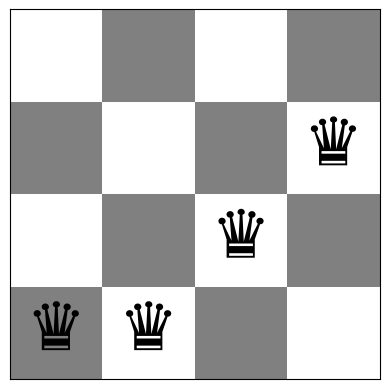

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


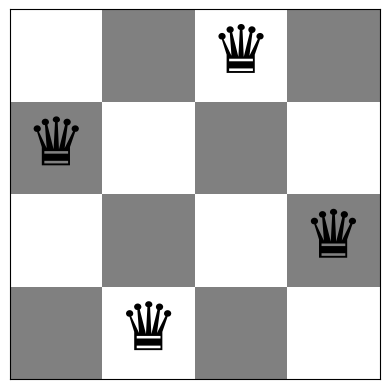

In [4]:
board = [1,3,0,2]
show_board(board)

Board with 8 conflicts.


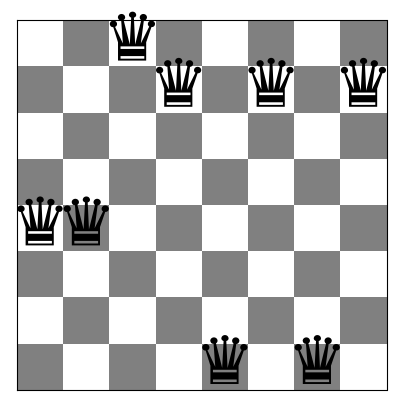

Queens (left to right) are at rows: [4 4 0 1 7 1 7 1]
Number of conflicts: 8


In [5]:
board = random_board(8)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [6]:
# Code and description go here

import time

def steepest_ascent_hill_climbing(n, initial_board=None):
    """Steepest-ascent Hill Climbing for n-Queens."""

    start_time = time.perf_counter()

    # Initialize the board
    if initial_board is None:
        board = random_board(n)
    else:
        board = np.array(initial_board, dtype=int).copy()

    current_score = int(conflicts(board))
    evaluations = 1
    iterations = 0
    history = [current_score]

    while current_score > 0:
        best_score = current_score
        best_board = None

        # Evaluate all n*(n-1) local moves
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue

                neighbor = board.copy()
                neighbor[col] = row

                score = int(conflicts(neighbor))
                evaluations += 1

                if score < best_score:
                    best_score = score
                    best_board = neighbor

        # Stop at a local optimum
        if best_board is None:
            break

        board = best_board
        current_score = best_score
        iterations += 1
        history.append(current_score)

    return {
        "board": board,
        "conflicts": current_score,
        "iterations": iterations,
        "evaluations": evaluations,
        "time_ms": (time.perf_counter() - start_time) * 1000,
        "history": history
    }


# Test with n=4 and n=8
for n in [4, 8]:
    result = steepest_ascent_hill_climbing(n)

    print(f"\nBoard size: {n}")
    print(f"Final board: {result['board']}")
    print(f"Conflicts: {result['conflicts']}")
    print(f"Iterations: {result['iterations']}")
    print(f"Evaluations: {result['evaluations']}")
    print(f"Time (ms): {result['time_ms']:.3f}")
    print(f"History: {result['history']}")



Board size: 4
Final board: [2 0 3 1]
Conflicts: 0
Iterations: 2
Evaluations: 25
Time (ms): 0.179
History: [5, 2, 0]

Board size: 8
Final board: [1 7 2 6 3 0 0 4]
Conflicts: 1
Iterations: 3
Evaluations: 225
Time (ms): 1.418
History: [9, 5, 3, 1]


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [7]:
import time


def inefficient_stochastic_hill_climbing(n, initial_board=None):
    """Choose a random improving neighbor after evaluating every local move."""
    if n < 1:
        raise ValueError("n must be positive")

    start = time.perf_counter()
    if initial_board is None:
        board = random_board(n)
    else:
        board = np.asarray(initial_board, dtype=int).copy()

    if board.shape != (n,) or np.any(board < 0) or np.any(board >= n):
        raise ValueError("initial_board must contain n row indices in [0, n)")

    current_score = int(conflicts(board))
    evaluations = 1
    iterations = 0
    history = [current_score]

    while current_score > 0:
        improving_moves = []

        # Evaluate all n * (n - 1) legal moves before choosing one.
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue
                neighbor = board.copy()
                neighbor[col] = row
                neighbor_score = int(conflicts(neighbor))
                evaluations += 1
                if neighbor_score < current_score:
                    improving_moves.append((neighbor, neighbor_score))

        if not improving_moves:
            break

        # Every improving neighbor is equally likely to be selected.
        selected = int(np.random.randint(len(improving_moves)))
        board, current_score = improving_moves[selected]
        iterations += 1
        history.append(current_score)

    return {
        "board": board,
        "conflicts": current_score,
        "iterations": iterations,
        "evaluations": evaluations,
        "time_ms": (time.perf_counter() - start) * 1000,
        "history": history,
        "stopped_reason": "solution" if current_score == 0 else "local_optimum",
    }


# Run the required n = 4 and n = 8 examples with a reproducible seed.
for n in [4, 8]:
    np.random.seed(1234)
    result = inefficient_stochastic_hill_climbing(n)

    print(f"\nBoard size: {n}")
    print(f"Final board: {result['board']}")
    print(f"Conflicts: {result['conflicts']}")
    print(f"Iterations: {result['iterations']}")
    print(f"Evaluations: {result['evaluations']}")
    print(f"Time (ms): {result['time_ms']:.3f}")
    print(f"History: {result['history']}")
    print(f"Stopped reason: {result['stopped_reason']}")



Board size: 4
Final board: [1 3 2 0]
Conflicts: 1
Iterations: 2
Evaluations: 37
Time (ms): 0.299
History: [4, 3, 1]
Stopped reason: local_optimum

Board size: 8
Final board: [7 2 0 5 1 4 6 3]
Conflicts: 0
Iterations: 6
Evaluations: 337
Time (ms): 2.095
History: [9, 6, 5, 4, 3, 2, 0]
Stopped reason: solution


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [8]:
# Code and description go here

import time

def efficient_stochastic_hill_climbing(
    n, initial_board=None, max_no_improve=None
):
    """
    Efficient Stochastic (First-choice) Hill Climbing.
    Generate one random neighbor at a time and accept
    it immediately if the number of conflicts decreases.
    """
    if n < 1:
        raise ValueError("n must be positive")

    start = time.perf_counter()

    # Initialize board
    if initial_board is None:
        board = random_board(n)
    else:
        board = np.array(initial_board, dtype=int).copy()

    if len(board) != n or np.any(board < 0) or np.any(board >= n):
        raise ValueError("Invalid initial board")

    current_score = int(conflicts(board))
    evaluations = 1
    iterations = 0
    history = [current_score]
    proposal_history = [current_score]

    # Number of possible local moves: n * (n - 1)
    neighbor_count = n * (n - 1)

    # Stop after too many consecutive failed attempts
    if max_no_improve is None:
        max_no_improve = max(1, 5 * neighbor_count)

    if max_no_improve < 1:
        raise ValueError("max_no_improve must be positive")

    failures = 0

    while current_score > 0 and failures < max_no_improve:

        # Select a random column
        col = np.random.randint(n)

        # Select a different row in the same column
        row = np.random.randint(n - 1)
        if row >= board[col]:
            row += 1

        # Generate one random neighbor
        neighbor = board.copy()
        neighbor[col] = row

        # Evaluate the neighbor
        new_score = int(conflicts(neighbor))
        evaluations += 1

        # Accept immediately if the neighbor is better
        if new_score < current_score:
            board = neighbor
            current_score = new_score
            iterations += 1
            history.append(current_score)

            # Reset consecutive failed attempts
            failures = 0
        else:
            failures += 1

        proposal_history.append(current_score)

    elapsed_ms = (time.perf_counter() - start) * 1000

    return {
        "board": board,
        "conflicts": current_score,
        "iterations": iterations,
        "evaluations": evaluations,
        "time_ms": elapsed_ms,
        "history": history,
        "proposal_history": proposal_history,
        "stopped_reason": (
            "solution" if current_score == 0
            else "no_improvement_limit"
        )
    }


# Experiments with n = 4 and n = 8
for n in [4, 8]:
    np.random.seed(1234)

    result = efficient_stochastic_hill_climbing(n)

    print(f"\nBoard size: {n}")
    print(f"Final board: {result['board']}")
    print(f"Conflicts: {result['conflicts']}")
    print(f"Iterations: {result['iterations']}")
    print(f"Evaluations: {result['evaluations']}")
    print(f"Time (ms): {result['time_ms']:.3f}")
    print(f"History: {result['history']}")
    print(f"Stopped reason: {result['stopped_reason']}")



Board size: 4
Final board: [1 3 0 2]
Conflicts: 0
Iterations: 3
Evaluations: 26
Time (ms): 0.344
History: [4, 3, 1, 0]
Stopped reason: solution

Board size: 8
Final board: [1 3 5 7 4 6 0 2]
Conflicts: 1
Iterations: 6
Evaluations: 331
Time (ms): 3.229
History: [9, 6, 5, 4, 3, 2, 1]
Stopped reason: no_improvement_limit


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [9]:
# Code and description go here

import time

def random_restart_hill_climbing(
    algorithm, n, max_restarts=100, initial_board=None
):
    """
    Random Restart Hill Climbing.

    Run a Hill Climbing algorithm from different
    random boards until a solution is found or
    the restart limit is reached.
    """
    if n < 1:
        raise ValueError("n must be positive")

    if max_restarts < 0:
        raise ValueError("max_restarts must be >= 0")

    start_time = time.perf_counter()

    best_result = None
    total_iterations = 0
    total_evaluations = 0
    restart_history = []
    full_history = []
    restart_boundaries = []

    # One initial run + at most max_restarts restarts
    for attempt in range(max_restarts + 1):

        # Generate a new random board
        start_board = (np.array(initial_board, dtype=int).copy()
                       if attempt == 0 and initial_board is not None else random_board(n))

        # Run the selected Hill Climbing algorithm
        result = algorithm(
            n, initial_board=start_board
        )

        restart_boundaries.append(len(full_history))
        full_history.extend(result.get("proposal_history", result["history"]))

        # Accumulate evaluation metrics
        total_iterations += result["iterations"]
        total_evaluations += result["evaluations"]

        # Keep the best solution across all runs
        if (
            best_result is None
            or result["conflicts"] < best_result["conflicts"]
        ):
            best_result = {
                **result,
                "board": result["board"].copy(),
                "history": result["history"].copy()
            }

        restart_history.append(
            best_result["conflicts"]
        )

        # Stop early when a valid solution is found
        if best_result["conflicts"] == 0:
            break

    elapsed_ms = (
        time.perf_counter() - start_time
    ) * 1000

    return {
        "board": best_result["board"],
        "conflicts": best_result["conflicts"],
        "iterations": total_iterations,
        "evaluations": total_evaluations,
        "time_ms": elapsed_ms,
        "history": best_result["history"],
        "restart_history": restart_history,
        "full_history": full_history,
        "restart_boundaries": restart_boundaries,
        "restarts": attempt,
        "runs": attempt + 1,
        "success": best_result["conflicts"] == 0
    }


# Test Task 4 with Task 1 and Task 3
algorithms = {
    "Steepest-ascent": steepest_ascent_hill_climbing,
    "Inefficient Stochastic": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic": efficient_stochastic_hill_climbing
}

for name, algorithm in algorithms.items():
    for n in [4, 8]:

        # Fixed seed for reproducible experiments
        np.random.seed(1234)

        result = random_restart_hill_climbing(
            algorithm, n, max_restarts=100, initial_board=None
        )

        print(f"\nAlgorithm: {name}")
        print(f"Board size: {n}")
        print(f"Best board: {result['board']}")
        print(f"Conflicts: {result['conflicts']}")
        print(f"Runs: {result['runs']}")
        print(f"Restarts: {result['restarts']}")
        print(f"Iterations: {result['iterations']}")
        print(f"Evaluations: {result['evaluations']}")
        print(f"Time (ms): {result['time_ms']:.3f}")
        print(f"Success: {result['success']}")
        print(f"Restart history: {result['restart_history']}")



Algorithm: Steepest-ascent
Board size: 4
Best board: [2 0 3 1]
Conflicts: 0
Runs: 2
Restarts: 1
Iterations: 3
Evaluations: 50
Time (ms): 0.306
Success: True
Restart history: [1, 0]

Algorithm: Steepest-ascent
Board size: 8
Best board: [0 4 7 5 2 6 1 3]
Conflicts: 0
Runs: 5
Restarts: 4
Iterations: 15
Evaluations: 1069
Time (ms): 7.310
Success: True
Restart history: [2, 1, 1, 1, 0]

Algorithm: Inefficient Stochastic
Board size: 4
Best board: [1 3 0 2]
Conflicts: 0
Runs: 4
Restarts: 3
Iterations: 7
Evaluations: 124
Time (ms): 0.585
Success: True
Restart history: [1, 1, 1, 0]

Algorithm: Inefficient Stochastic
Board size: 8
Best board: [7 2 0 5 1 4 6 3]
Conflicts: 0
Runs: 1
Restarts: 0
Iterations: 6
Evaluations: 337
Time (ms): 2.274
Success: True
Restart history: [0]

Algorithm: Efficient Stochastic
Board size: 4
Best board: [1 3 0 2]
Conflicts: 0
Runs: 1
Restarts: 0
Iterations: 3
Evaluations: 26
Time (ms): 0.194
Success: True
Restart history: [0]

Algorithm: Efficient Stochastic
Board si

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

### Cách triển khai và thiết kế thực nghiệm

Hàm trong `simulated_annealing.py` ghi lại từng lần đề xuất, kể cả khi bước đi bị từ chối. Thuật toán dừng khi số xung đột bằng 0, nhiệt độ chạm ngưỡng tối thiểu hoặc đã thử 1.000 bước đi. Với số vòng lặp hữu hạn, thuật toán không bảo đảm tìm được lời giải. Quy tắc chấp nhận bước đi theo nhiệt độ được tham khảo từ [UC Berkeley CS188: Local Search](https://inst.eecs.berkeley.edu/~cs188/textbook/search/local.html).

Thực nghiệm so sánh lịch giảm nhiệt **tuyến tính (linear)** $T_t=T_0-\eta t$ và **hàm mũ (exponential)** $T_t=T_0\alpha^t$, với $T_0\in\{0.4,2.0\}$ và $T_{min}=10^{-8}$. Với giới hạn $K=1000$ vòng lặp, chọn $\eta=(T_0-T_{min})/K$ hoặc $\alpha=(T_{min}/T_0)^{1/K}$. Hai lịch cùng hướng đến một nhiệt độ cuối nhưng có quá trình giảm nhiệt khác nhau. Nhiệt độ được giới hạn để không thấp hơn ngưỡng dương tối thiểu.

Với mỗi kích thước (4 và 8), tạo 100 bàn cờ ban đầu khác nhau và dùng chung cho mọi cấu hình. Các lần chạy tương ứng cũng dùng cùng seed của bộ sinh số ngẫu nhiên, dù các quyết định chấp nhận bước đi có thể khiến chuỗi số ngẫu nhiên được sử dụng về sau khác nhau. Các chỉ số gồm tỷ lệ thành công, số xung đột tốt nhất trung bình, số vòng lặp trung bình và thời gian chạy trung bình trên **tất cả** các lần chạy, kể cả những lần thất bại. Đây là thực nghiệm lựa chọn lịch giảm nhiệt; dữ liệu này không phải tập kiểm chứng độc lập. Biểu đồ minh họa lần chạy thứ nhất, được chọn trước khi xem kết quả, thay vì chọn lần chạy tốt nhất.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from simulated_annealing import simulated_annealing
from helper import create_experiment_id, save_log_result, summarize_experiment
from pathlib import Path
import json

# Mỗi lần chạy cell tạo một thư mục riêng, không trộn với thực nghiệm cũ.
sa_task5_experiment_id = create_experiment_id("task5_SA_schedules")
sa_task5_log_dir = Path("logs") / sa_task5_experiment_id
sa_task5_image_dir = Path("img/task_5_SA") / sa_task5_experiment_id
sa_task5_log_dir.mkdir(parents=True, exist_ok=True)
sa_task5_image_dir.mkdir(parents=True, exist_ok=True)

SA_TASK5_RUNS = 100
SA_TASK5_BUDGET = 1000
sa_task5_configs = [
    {"label": "Linear T0=0.4", "mode": 0, "initial_temperature": 0.4},
    {"label": "Linear T0=2.0", "mode": 0, "initial_temperature": 2.0},
    {"label": "Exponential T0=0.4", "mode": 1, "initial_temperature": 0.4},
    {"label": "Exponential T0=2.0", "mode": 1, "initial_temperature": 2.0},
]
board_rng = np.random.RandomState(2026)
sa_task5_boards = {}
for size in (4, 8):
    boards, seen = [], set()
    while len(boards) < SA_TASK5_RUNS:
        candidate = tuple(board_rng.randint(size, size=size))
        if candidate not in seen:
            seen.add(candidate)
            boards.append(np.array(candidate))
    sa_task5_boards[size] = boards

sa_task5_rows, sa_task5_examples = [], {}
for size, boards in sa_task5_boards.items():
    for config in sa_task5_configs:
        for run, initial_board in enumerate(boards, start=1):
            result = simulated_annealing(
                n=size, board=initial_board, seed=10000 + size * 100 + run,
                mode=config["mode"], initial_temperature=config["initial_temperature"],
                max_iterations=SA_TASK5_BUDGET,
            )
            # Lưu lịch sử cho mọi run; chỉ vẽ ảnh riêng cho run 1 mỗi cấu hình/kích thước.
            save_log_result(
                result, algorithm=f"Simulated Annealing - {config['label']}",
                experiment_id=sa_task5_experiment_id, run_number=run,
                plot_run=(run == 1), show_plot=False, verbose=False,
            )
            sa_task5_rows.append({
                "n": size, "configuration": config["label"], "run": run,
                "success": result["best_conflicts"] == 0,
                "best_conflicts": result["best_conflicts"],
                "iterations": result["iterations"], "runtime_ms": result["runtime_ms"],
            })
            if run == 1:
                sa_task5_examples[size, config["label"]] = result

# Tổng hợp một lần sau batch, không đọc/ghi lại bảng cho mỗi run.
summarize_experiment(sa_task5_experiment_id, show_plot=False, verbose=False)

sa_task5_results = pd.DataFrame(sa_task5_rows)
sa_task5_summary = sa_task5_results.groupby(["n", "configuration"], sort=False).agg(
    runs=("success", "size"), success_pct=("success", lambda x: 100*x.mean()),
    mean_best_conflicts=("best_conflicts", "mean"),
    mean_iterations=("iterations", "mean"), mean_runtime_ms=("runtime_ms", "mean"),
).reset_index()
with pd.option_context("display.max_columns", None):
    display(sa_task5_summary.round(3))

# Lưu cả bảng dùng trong Task 5 và cấu hình để đọc lại khi làm Task 6.
sa_task5_results.to_csv(sa_task5_log_dir / "schedule_runs.csv", index=False)
sa_task5_summary.to_csv(sa_task5_log_dir / "schedule_summary.csv", index=False)
sa_task5_manifest = {
    "experiment_id": sa_task5_experiment_id,
    "runs_per_size_per_configuration": SA_TASK5_RUNS,
    "board_sizes": [4, 8], "max_iterations": SA_TASK5_BUDGET,
    "min_temperature": 1e-8, "board_seed": 2026,
    "run_seed_rule": "10000 + size * 100 + run (run starts at 1)",
    "representative_run": 1, "configurations": sa_task5_configs,
    "starting_boards": {str(size): [board.tolist() for board in boards]
                        for size, boards in sa_task5_boards.items()},
}
(sa_task5_log_dir / "experiment.json").write_text(
    json.dumps(sa_task5_manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Thư mục log:", sa_task5_log_dir)
print("Thư mục ảnh:", sa_task5_image_dir)


,n,configuration,runs,success_pct,mean_best_conflicts,mean_iterations,mean_runtime_ms
0,4,Linear T0=0.4,100,100.0,0.00,40.14,0.326
1,4,Linear T0=2.0,100,100.0,0.00,83.64,0.629
2,4,Exponential T0=0.4,100,100.0,0.00,38.21,0.316
3,4,Exponential T0=2.0,100,100.0,0.00,59.51,0.470
4,8,Linear T0=0.4,100,76.0,0.24,508.21,4.661
5,8,Linear T0=2.0,100,41.0,0.61,908.02,8.505
6,8,Exponential T0=0.4,100,78.0,0.22,471.27,4.601
7,8,Exponential T0=2.0,100,77.0,0.23,487.25,4.986


Thư mục log: logs/task5_SA_schedules_20261021_214958_702918
Thư mục ảnh: img/task_5_SA/task5_SA_schedules_20261021_214958_702918


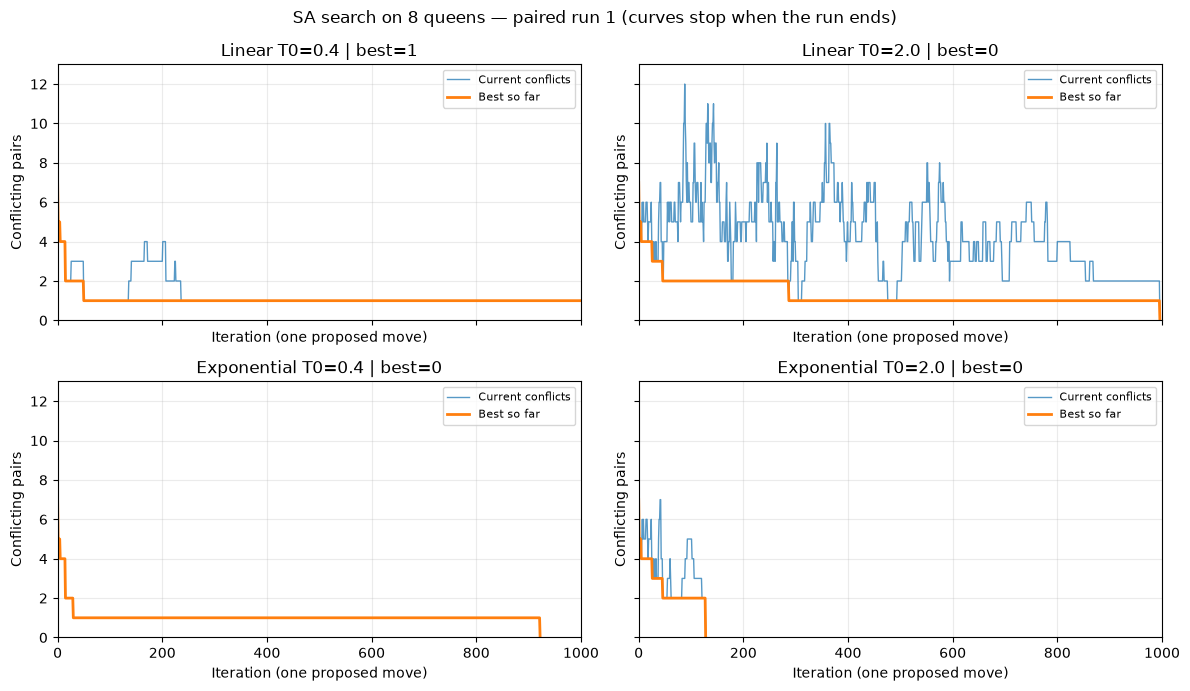

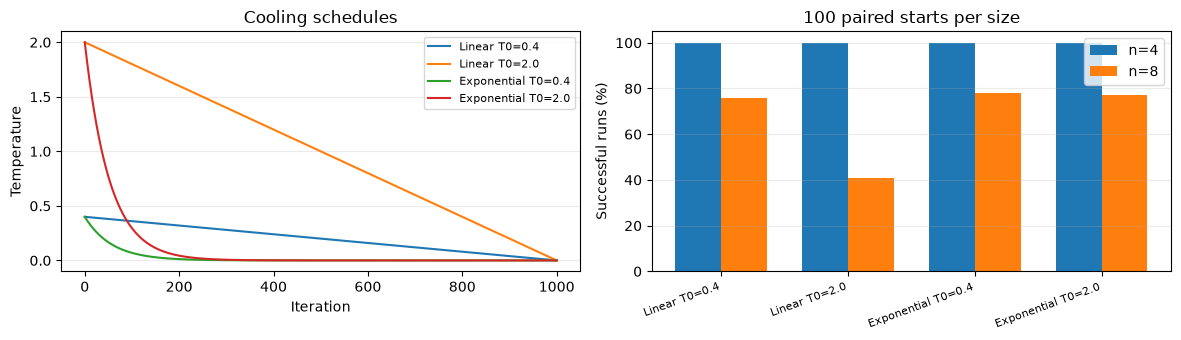

In [11]:
# Each panel uses the same preselected n=8 starting board and seed.
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, config in zip(axes.flat, sa_task5_configs):
    result = sa_task5_examples[8, config["label"]]
    history = pd.DataFrame(result["history"])
    ax.plot(history["iteration"], history["conflicts"], alpha=0.75,
            linewidth=1, label="Current conflicts")
    ax.plot(history["iteration"], history["best_conflicts"],
            linewidth=2, label="Best so far")
    ax.set_title(f"{config['label']} | best={result['best_conflicts']}")
    ax.set_xlabel("Iteration (one proposed move)")
    ax.set_ylabel("Conflicting pairs")
    ax.set_xlim(0, SA_TASK5_BUDGET)
    ax.set_ylim(0, 1 + max(
        step["conflicts"]
        for config_item in sa_task5_configs
        for step in sa_task5_examples[8, config_item["label"]]["history"]
    ))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("SA search on 8 queens — paired run 1 (curves stop when the run ends)")
fig.tight_layout()
fig.savefig(sa_task5_image_dir / "convergence_n8.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot the prescribed full schedule, even if a search finds a solution early.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
steps = np.arange(SA_TASK5_BUDGET + 1)
for config in sa_task5_configs:
    t0 = config["initial_temperature"]
    if config["mode"] == 0:
        temperatures = t0 - (t0 - 1e-8) * steps / SA_TASK5_BUDGET
    else:
        temperatures = t0 * ((1e-8 / t0)**(1 / SA_TASK5_BUDGET))**steps
    axes[0].plot(steps, np.maximum(temperatures, 1e-8), label=config["label"])
axes[0].set(xlabel="Iteration", ylabel="Temperature", title="Cooling schedules")
axes[0].legend(fontsize=8)
labels = [c["label"] for c in sa_task5_configs]
x = np.arange(len(labels))
for offset, size in [(-0.18, 4), (0.18, 8)]:
    rates = sa_task5_summary.query("n == @size").set_index("configuration").loc[labels, "success_pct"]
    axes[1].bar(x + offset, rates, width=0.36, label=f"n={size}")
axes[1].set_xticks(x, labels, rotation=20, ha="right", fontsize=8)
axes[1].set(ylabel="Successful runs (%)", ylim=(0, 105), title="100 paired starts per size")
axes[1].legend()
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(sa_task5_image_dir / "schedules_and_success.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Tạo nhận xét từ kết quả của lần thực thi hiện tại để số liệu luôn khớp.
ranked = sa_task5_summary.query("n == 8").sort_values(
    ["success_pct", "mean_best_conflicts", "mean_iterations"], ascending=[False, True, True]
)
winner = ranked.iloc[0]
lines = ["### Nhận xét từ kết quả thực nghiệm"]
for size in (4, 8):
    lines.append(f"**n={size}:** " + "; ".join(
        f"{row.configuration}: {row.success_pct:.0f}% thành công, "
        f"{row.mean_best_conflicts:.2f} xung đột tốt nhất trung bình"
        for row in sa_task5_summary.query("n == @size").itertuples()) + ".")
lines.append(
    f"Với n=8, **{winner['configuration']}** đứng đầu trong bốn cấu hình đã thử "
    f"({winner['success_pct']:.0f}% thành công; {winner['mean_iterations']:.1f} lượt đề xuất trung bình). "
    "Xếp hạng ưu tiên tỷ lệ thành công, sau đó là số xung đột tốt nhất trung bình, rồi đến số lượt đề xuất trung bình. "
    "Đề xuất này chỉ dựa trên phạm vi thực nghiệm hiện tại, chưa chứng minh đây là lịch giảm nhiệt tốt nhất cho mọi trường hợp."
)
for config in sa_task5_configs:
    h = pd.DataFrame(sa_task5_examples[8, config["label"]]["history"])
    diff = h["conflicts"].diff().dropna()
    lines.append(
        f"Lần chạy 1, **{config['label']}**: {len(diff)} lượt đề xuất, "
        f"{int((diff > 0).sum())} lần tăng số xung đột, "
        f"{int((diff == 0).sum())} bước giữ nguyên số xung đột; "
        f"số xung đột tốt nhất là {int(h['best_conflicts'].iloc[-1])}."
    )
sa_task5_observations = "\n\n".join(lines)
(sa_task5_log_dir / "observations.md").write_text(sa_task5_observations, encoding="utf-8")
display(Markdown(sa_task5_observations))

### Nhận xét từ kết quả thực nghiệm

**n=4:** Linear T0=0.4: 100% thành công, 0.00 xung đột tốt nhất trung bình; Linear T0=2.0: 100% thành công, 0.00 xung đột tốt nhất trung bình; Exponential T0=0.4: 100% thành công, 0.00 xung đột tốt nhất trung bình; Exponential T0=2.0: 100% thành công, 0.00 xung đột tốt nhất trung bình.

**n=8:** Linear T0=0.4: 76% thành công, 0.24 xung đột tốt nhất trung bình; Linear T0=2.0: 41% thành công, 0.61 xung đột tốt nhất trung bình; Exponential T0=0.4: 78% thành công, 0.22 xung đột tốt nhất trung bình; Exponential T0=2.0: 77% thành công, 0.23 xung đột tốt nhất trung bình.

Với n=8, **Exponential T0=0.4** đứng đầu trong bốn cấu hình đã thử (78% thành công; 471.3 lượt đề xuất trung bình). Xếp hạng ưu tiên tỷ lệ thành công, sau đó là số xung đột tốt nhất trung bình, rồi đến số lượt đề xuất trung bình. Đề xuất này chỉ dựa trên phạm vi thực nghiệm hiện tại, chưa chứng minh đây là lịch giảm nhiệt tốt nhất cho mọi trường hợp.

Lần chạy 1, **Linear T0=0.4**: 1000 lượt đề xuất, 6 lần tăng số xung đột, 986 bước giữ nguyên số xung đột; số xung đột tốt nhất là 1.

Lần chạy 1, **Linear T0=2.0**: 996 lượt đề xuất, 127 lần tăng số xung đột, 733 bước giữ nguyên số xung đột; số xung đột tốt nhất là 0.

Lần chạy 1, **Exponential T0=0.4**: 922 lượt đề xuất, 0 lần tăng số xung đột, 917 bước giữ nguyên số xung đột; số xung đột tốt nhất là 0.

Lần chạy 1, **Exponential T0=2.0**: 128 lượt đề xuất, 16 lần tăng số xung đột, 94 bước giữ nguyên số xung đột; số xung đột tốt nhất là 0.

### Các tệp kết quả được lưu

Mỗi lần chạy cell thực nghiệm sẽ tạo một `experiment_id` mới. Đường dẫn cụ thể được in bên dưới bảng kết quả. Hàm `save_log_result()` trong `helper.py` được dùng để lưu:

- `logs/<experiment_id>/runs.csv`: kết quả của 800 lần chạy, kèm bàn cờ ban đầu, seed, cấu hình nhiệt độ và bàn cờ tốt nhất.
- `logs/<experiment_id>/histories/<algorithm_hash>/n<size>/run_000001.csv.gz`: lịch sử từng vòng lặp của mỗi lần chạy, dùng để vẽ lại quá trình hội tụ.
- `logs/<experiment_id>/summary.csv`: bảng tổng hợp theo cấu hình SA và kích thước bàn cờ. Tên cấu hình được đưa vào trường `algorithm` để không gộp nhầm các lịch giảm nhiệt.
- `schedule_runs.csv` và `schedule_summary.csv`: dữ liệu và bảng tổng hợp đúng định dạng đang trình bày trong Task 5.
- `experiment.json`: thông số thực nghiệm và tập bàn cờ ban đầu; `observations.md`: nhận xét có số liệu của lần thực thi.
- `img/task_5_SA/<experiment_id>/runs/`: 8 ảnh minh họa lần chạy thứ nhất (4 cấu hình × 2 kích thước).
- `img/task_5_SA/<experiment_id>/convergence_n8.png` và `schedules_and_success.png`: hai hình tổng hợp hiển thị trong notebook.

Để dùng lại cho Task 6 sau khi khởi động lại kernel, đọc `runs.csv` hoặc `summary.csv` bằng `pd.read_csv()` và chọn một cấu hình SA cố định. Cột `history_csv` trong `runs.csv` chỉ tới lịch sử tương ứng (đường dẫn tương đối trong experiment). Đọc bằng `pd.read_csv(path)`; pandas tự giải nén gzip. Với file lớn, dùng `pd.read_csv(path, chunksize=10000)` để đọc từng phần. Metadata chỉ lưu một lần trong `runs.csv`, không lặp lại ở mỗi bước. Có thể truyền `save_history=False` khi chỉ cần metrics. `summary.csv` được tạo một lần sau batch bằng `summarize_experiment()`. Log cũ được giữ nguyên; luôn tạo experiment mới khi dùng định dạng mới. Mỗi experiment có thể được lưu trữ hoặc xóa riêng sau khi kiểm tra kết quả. Không cần chạy lại SA để tính các chỉ số hoặc vẽ lại từ dữ liệu đã lưu. Số liệu này chỉ gồm `n=4,8`; các kích thước lớn hơn vẫn cần thực nghiệm bổ sung.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC | 4 | 0.097 ms | 0.65 | 45% |
| Ineff. Stochastic HC | 4 | 0.127 ms | 0.94 | 26% |
| Efficient Stochastic HC | 4 | 0.339 ms | 0.85 | 34% |
| Simulated Annealing | 4 | 0.324 ms | 0.00 | 100% |
| Steepest asc. HC | 8 | 1.334 ms | 1.14 | 14% |
| Ineff. Stochastic HC | 8 | 1.838 ms | 1.22 | 15% |
| Efficient Stochastic HC | 8 | 2.576 ms | 1.29 | 13% |
| Simulated Annealing | 8 | 4.389 ms | 0.22 | 78% |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

**Thiết lập:** 100 bàn cờ khác nhau cho mỗi kích thước, dùng chung giữa các thuật toán. SA dùng lại log cấu hình `Exponential T0=0.4`, tối đa 1.000 bước. HC chỉ chấp nhận bước giảm xung đột; Efficient HC dừng sau $5n(n-1)$ lần thử liên tiếp không cải thiện. Random restart cho phép thêm tối đa 100 lần khởi động lại và được báo cáo riêng.

Chạy các cell định nghĩa thuật toán ở Task 1–4 trước. Kết quả HC và lịch sử được lưu từng run; chạy lại đọc cache. Khi sửa thuật toán, cần đổi hoặc xóa thư mục cache `task6_all_algorithms_v2`.

Cache HC/random restart dùng `runs.csv` và `histories/<algorithm_hash>/n<size>/run_000001.csv.gz`. Bảng chung với SA nằm ở `analysis_runs.csv`; `summary.csv` tổng hợp tất cả thuật toán. SA cho n=12,16,20 dùng thư mục riêng `<task5_experiment_id>_task6_scalability_v2`. Cache v1 được giữ nguyên, lần đầu dùng v2 sẽ thực nghiệm lại.


In [13]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown
from task6_analysis import resolve_task5_source, run_analysis, plot_convergence, plot_scaling

TASK6_SOURCE = resolve_task5_source()
task6_algorithms = {
    "Steepest-ascent HC": steepest_ascent_hill_climbing,
    "Inefficient Stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing,
}
task6_runs, task6_summary, task6_examples, task6_output, task6_images = run_analysis(
    task6_algorithms, random_restart_hill_climbing, TASK6_SOURCE
)
task6_core = task6_summary.loc[~task6_summary.algorithm.str.startswith("Restart ")]
task6_comparison = task6_core.loc[task6_core.board_size.isin([4, 8])].sort_values(["board_size", "algorithm"])
task6_restarts = task6_summary.loc[task6_summary.algorithm.str.startswith("Restart ")]
with pd.option_context("display.max_columns", None, "display.width", 150):
    display(task6_comparison.round(3))
    display(Markdown("**Random restart — ngân sách tối đa 101 lần chạy mỗi run:**"))
    display(task6_restarts.round(3))
task6_comparison.to_csv(task6_output / "comparison.csv", index=False)
task6_restarts.to_csv(task6_output / "restart_comparison.csv", index=False)
print("Log:", task6_output)
print("Ảnh:", task6_images)


,algorithm,board_size,runs,avg_runtime_ms,avg_conflicts,success_pct
19,Efficient Stochastic HC,4,100,0.361,0.85,34.0
12,Inefficient Stochastic HC,4,100,0.163,0.94,26.0
0,Simulated Annealing,4,100,0.316,0.00,100.0
5,Steepest-ascent HC,4,100,0.104,0.65,45.0
20,Efficient Stochastic HC,8,100,2.712,1.29,13.0
13,Inefficient Stochastic HC,8,100,1.959,1.22,15.0
1,Simulated Annealing,8,100,4.601,0.22,78.0
6,Steepest-ascent HC,8,100,1.393,1.14,14.0


**Random restart — ngân sách tối đa 101 lần chạy mỗi run:**

,algorithm,board_size,runs,avg_runtime_ms,avg_conflicts,success_pct
10,Restart Steepest-ascent HC,4,100,0.266,0.0,100.0
11,Restart Steepest-ascent HC,8,100,9.925,0.0,100.0
17,Restart Inefficient Stochastic HC,4,100,0.438,0.0,100.0
18,Restart Inefficient Stochastic HC,8,100,12.083,0.0,100.0
24,Restart Efficient Stochastic HC,4,100,1.066,0.0,100.0
25,Restart Efficient Stochastic HC,8,100,24.989,0.0,100.0


Log: logs/task5_SA_schedules_20261021_214958_702918/task6_all_algorithms_v2
Ảnh: img/task_6_all/task5_SA_schedules_20261021_214958_702918/v2


**Kết quả chính:** ở n=8, HC đơn đạt 13–15% thành công, SA đạt 78%; ba bản random restart đạt 100% nhưng tốn nhiều thời gian hơn. Efficient HC ít tốn chi phí mỗi lượt thử, nhưng có thể chậm hơn do thử nhiều bước không cải thiện.

`avg_runtime_ms`: thời gian đến khi dừng; `avg_conflicts`: xung đột của kết quả trả về; `success_pct`: tỷ lệ đạt 0 xung đột. Không tính ghi log/vẽ hình. SA được chọn cấu hình trên chính tập này và đo thời gian ở lần thực thi khác HC.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

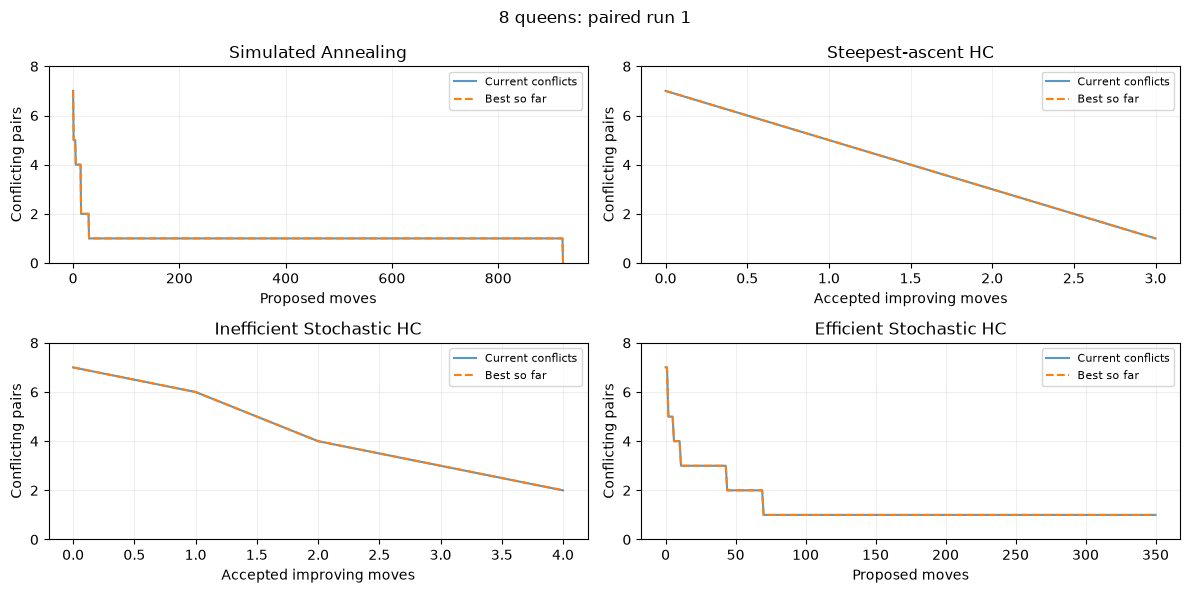

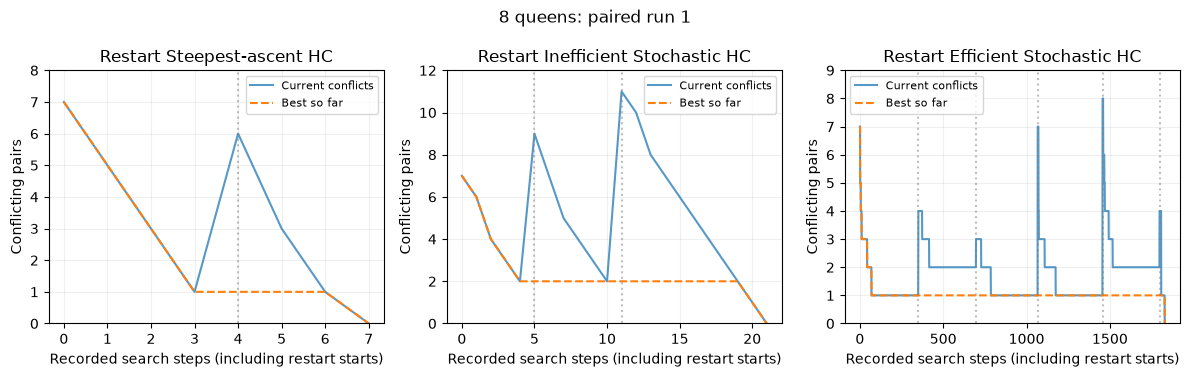

,algorithm,unsolved_pct
20,Efficient Stochastic HC,87.0
13,Inefficient Stochastic HC,85.0
1,Simulated Annealing,22.0
6,Steepest-ascent HC,86.0


**Nhận xét:** Steepest HC giảm nhanh nhờ chọn bước tốt nhất; Stochastic HC cải thiện không đều. Efficient HC có đoạn nằm ngang do các lượt thử không cải thiện. SA có thể chấp nhận bước xấu hơn, còn random restart thoát vùng mắc kẹt bằng bàn cờ mới (vạch chấm). Ở n=8, tỷ lệ chưa giải được cao nhất là Efficient Stochastic HC (87%). Thất bại hoặc đoạn bằng phẳng chưa đủ chứng minh cực tiểu cục bộ. Các trục X dùng đơn vị khác nhau như nhãn; không so chi phí bằng độ dài đường.

In [14]:
plot_convergence(task6_examples, task6_images)
# Tỷ lệ thất bại được tổng hợp từ 100 run, không suy ra từ một biểu đồ.
task6_failure = task6_comparison.loc[task6_comparison.board_size.eq(8), ["algorithm", "success_pct"]].copy()
task6_failure["unsolved_pct"] = 100-task6_failure.pop("success_pct")
display(task6_failure)
worst = task6_failure.loc[task6_failure.unsolved_pct.eq(task6_failure.unsolved_pct.max())]
task6_convergence_note = (
    "**Nhận xét:** Steepest HC giảm nhanh nhờ chọn bước tốt nhất; Stochastic HC cải thiện không đều. "
    "Efficient HC có đoạn nằm ngang do các lượt thử không cải thiện. SA có thể chấp nhận bước xấu hơn, "
    "còn random restart thoát vùng mắc kẹt bằng bàn cờ mới (vạch chấm). "
    "Ở n=8, tỷ lệ chưa giải được cao nhất là " + ", ".join(worst.algorithm)
    + f" ({worst.unsolved_pct.iloc[0]:.0f}%). "
    "Thất bại hoặc đoạn bằng phẳng chưa đủ chứng minh cực tiểu cục bộ. "
    "Các trục X dùng đơn vị khác nhau như nhãn; không so chi phí bằng độ dài đường."
)
display(Markdown(task6_convergence_note))
(task6_output / "convergence_notes.md").write_text(task6_convergence_note, encoding="utf-8");


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

,algorithm,board_size,runs,avg_runtime_ms,avg_conflicts,success_pct
0,Simulated Annealing,4,100,0.316,0.00,100.0
1,Simulated Annealing,8,100,4.601,0.22,78.0
2,Simulated Annealing,12,100,9.691,0.66,37.0
3,Simulated Annealing,16,100,13.563,1.05,15.0
4,Simulated Annealing,20,100,15.990,1.36,10.0
5,Steepest-ascent HC,4,100,0.104,0.65,45.0
6,Steepest-ascent HC,8,100,1.393,1.14,14.0
7,Steepest-ascent HC,12,100,6.539,1.72,7.0
8,Steepest-ascent HC,16,100,18.813,2.07,3.0
9,Steepest-ascent HC,20,100,44.220,2.40,1.0


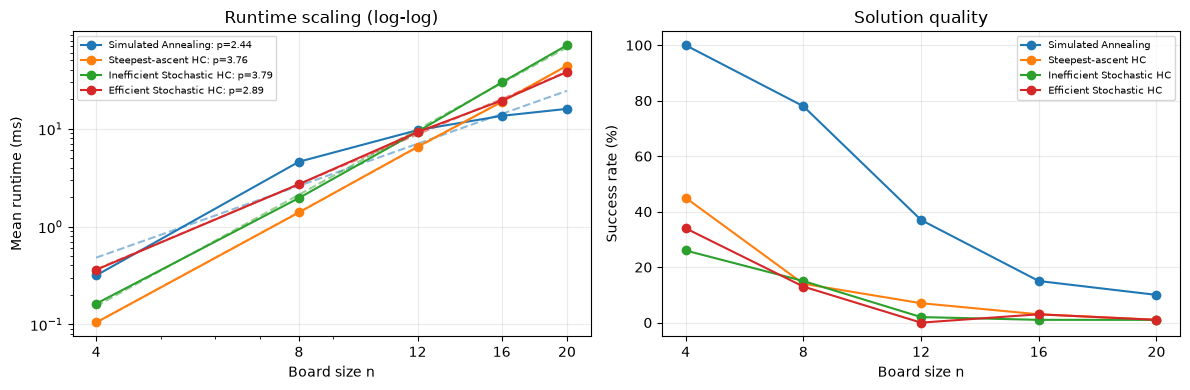

,algorithm,empirical_exponent,r_squared
0,Simulated Annealing,2.442,0.925
1,Steepest-ascent HC,3.757,1.000
2,Inefficient Stochastic HC,3.787,0.999
3,Efficient Stochastic HC,2.892,1.000


**Nhận xét:** tại n=20, Simulated Annealing dừng nhanh nhất (15.99 ms, thành công 10%). Simulated Annealing cũng có số mũ tăng thời gian nhỏ nhất. Mô hình O(n^p) chỉ là ước lượng thực nghiệm trên 5 kích thước, không phải cận lý thuyết. Steepest/Inefficient HC tốn O(n³) mỗi vòng duyệt hàng xóm; Efficient HC/SA tốn O(n) mỗi lượt thử. Tổng chi phí phụ thuộc số lượt: SA giới hạn 1.000, còn ngưỡng chờ Efficient HC tăng theo n². Cần xem kèm tỷ lệ thành công: dừng nhanh chưa chắc giải tốt.

In [15]:
with pd.option_context("display.max_columns", None, "display.width", 150):
    display(task6_core.round(3))
task6_fit = plot_scaling(task6_summary, task6_output, task6_images)
display(task6_fit.round(3))
large = task6_core.loc[task6_core.board_size.eq(20)].sort_values("avg_runtime_ms")
fastest = large.iloc[0]
slowest_exponent = task6_fit.sort_values("empirical_exponent").iloc[0]
task6_scaling_note = (
    f"**Nhận xét:** tại n=20, {fastest.algorithm} dừng nhanh nhất "
    f"({fastest.avg_runtime_ms:.2f} ms, thành công {fastest.success_pct:.0f}%). "
    f"{slowest_exponent.algorithm} cũng có số mũ tăng thời gian nhỏ nhất. "
    "Mô hình O(n^p) chỉ là ước lượng thực nghiệm trên 5 kích thước, không phải cận lý thuyết. "
    "Steepest/Inefficient HC tốn O(n³) mỗi vòng duyệt hàng xóm; Efficient HC/SA tốn O(n) mỗi lượt thử. "
    "Tổng chi phí phụ thuộc số lượt: SA giới hạn 1.000, còn ngưỡng chờ Efficient HC tăng theo n². "
    "Cần xem kèm tỷ lệ thành công: dừng nhanh chưa chắc giải tốt."
)
display(Markdown(task6_scaling_note))
(task6_output / "scalability_notes.md").write_text(task6_scaling_note, encoding="utf-8");


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [16]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [17]:
# Code and description go here